# A mechanistic carbon-cycle box model

**Question.** Can a carbon-cycle model built from physical and chemical rules reproduce the CO₂ rise measured at Mauna Loa from historical emissions, without fitting it to the CO₂ record?

**Model.** Four boxes: atmosphere, surface ocean, deep ocean and land. The ocean part is BEAM ([Glotter et al. 2014](https://climate.fas.harvard.edu/sites/projects.iq.harvard.edu/files/climate/files/glotter_etal_2014.pdf)), which computes ocean uptake from carbonate chemistry. The land box adds plant growth that responds to CO₂. The equations are in `box_model.py`.

**Plan.**
1. Check the code: the chemistry matches the paper, and an equilibrium stays put.
2. **Test 1, literature parameters only:** the Joos et al. (2013) pulse test, then the historical run.
3. Find which mechanism causes the misses.
4. **Test 2:** set the two least certain physical rates from *ocean* and *land* data alone, then predict the atmosphere, which is never used to set anything.
5. Limitations.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from box_model import Params, params_at, chemistry_at, equilibrium_state, revelle_factor, GTC_PER_PPM
from data_loader import gcb_budget, mauna_loa, noaa_global, observed_co2, ice_core_reconstruction
from experiments import *
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False})
g = gcb_budget()
LIT = Params()
LIT

Params(k_a=0.2, k_d=0.05, delta=50.0, k1=8e-07, k2=4.53e-10, kH=1230.0, AM=1.77e+20, OM=7.8e+22, MUP_ref=713.0, pH_ref=8.29, NPP0=60.0, beta=0.4, tau_L=35.0, land=True)

## 1. Is the code right?

The temperature formulas from the paper (Eqs. 14–16) should reproduce its Table 2. At pH 8.29, the paper's pre-industrial surface ocean (713 GtC) should be in equilibrium with 280 ppm. The automated versions of these checks are in `tests/`.

In [2]:
rows = []
for T, (k1, k2, invA) in {10: (8.00e-7, 4.63e-10, 7.02e-3), 12: (8.30e-7, 4.94e-10, 6.58e-3), 15: (8.75e-7, 5.47e-10, 6.00e-3)}.items():
    c = chemistry_at(T); p = Params(**c)
    rows.append({"T (C)": T, "k1 model": c["k1"], "k1 paper": k1, "k2 model": c["k2"], "k2 paper": k2, "1/A model": 1/p.A, "1/A paper": invA})
display(pd.DataFrame(rows).set_index("T (C)").style.format("{:.3g}"))
s = equilibrium_state(280, LIT)
print(f"Surface ocean in equilibrium with 280 ppm: {s[1]:.1f} GtC (paper: 713). Alkalinity: {LIT.alk:.1f} GtC (paper: 767).")

,k1 model,k1 paper,k2 model,k2 paper,1/A model,1/A paper
T (C),,,,,,
10,7.98e-07,8e-07,4.63e-10,4.63e-10,0.00701,0.00702
12,8.29e-07,8.3e-07,4.94e-10,4.94e-10,0.00657,0.00658
15,8.74e-07,8.75e-07,5.47e-10,5.47e-10,0.00598,0.006


Surface ocean in equilibrium with 280 ppm: 713.0 GtC (paper: 713). Alkalinity: 766.4 GtC (paper: 767).


## 2. Test 1: literature parameters only

### 2a. The Joos et al. (2013) pulse test

Joos et al. ran 15 models with the atmosphere held at 389 ppm and then added 100 GtC. After 1,000 years, **25 ± 9%** was still in the air, **59 ± 12%** in the ocean and **16 ± 14%** on land. The set-up here is the same: the observed CO₂ history up to 2010, then a fixed 389 ppm, then the pulse. The pulse is spread over its first year because BEAM can't take an instant jump.

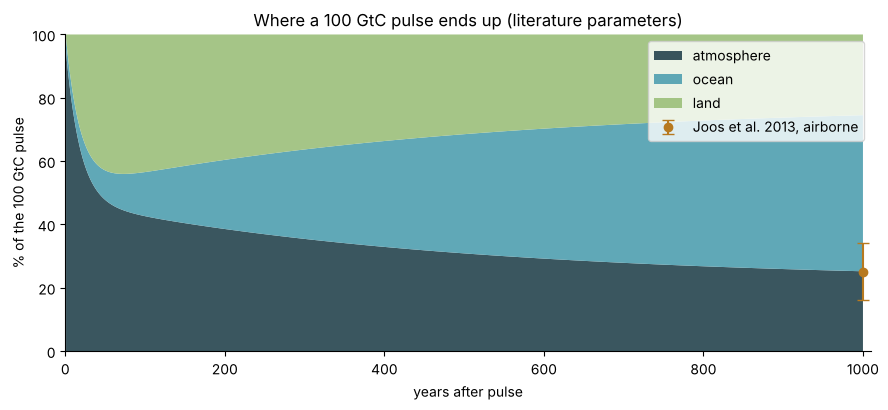

After 1000 yr: atmosphere 25.2% (published 25 ± 9%), ocean 49.3% (59 ± 12%), land 25.5% (16 ± 14%)


In [3]:
pl = pulse_test(LIT)
t = np.arange(1, 1001)
fig, ax = plt.subplots()
ax.stackplot(t, pl["atm"]*100, pl["ocean"]*100, pl["land"]*100, labels=["atmosphere", "ocean", "land"],
             colors=["#24434d", "#4f9fb0", "#9bbf7a"], alpha=.9)
for y, (c, u), col in [(25, JOOS_ATM_1000, "k")]:
    ax.errorbar([1000], [c*100], yerr=[u*100], fmt="o", color="#b7791f", capsize=4, label="Joos et al. 2013, airborne")
ax.set(xlabel="years after pulse", ylabel="% of the 100 GtC pulse", xlim=(0, 1010), ylim=(0, 100),
       title="Where a 100 GtC pulse ends up (literature parameters)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()
print(f"After 1000 yr: atmosphere {pl['atm'][-1]:.1%} (published 25 ± 9%), ocean {pl['ocean'][-1]:.1%} (59 ± 12%), land {pl['land'][-1]:.1%} (16 ± 14%)")

### 2b. Historical run, 1850–2024

The model is driven by Global Carbon Budget 2025 emissions: fossil fuel minus cement carbonation, plus land-use change. It starts in equilibrium at the 1850 ice-core value. The atmosphere is predicted, not prescribed.

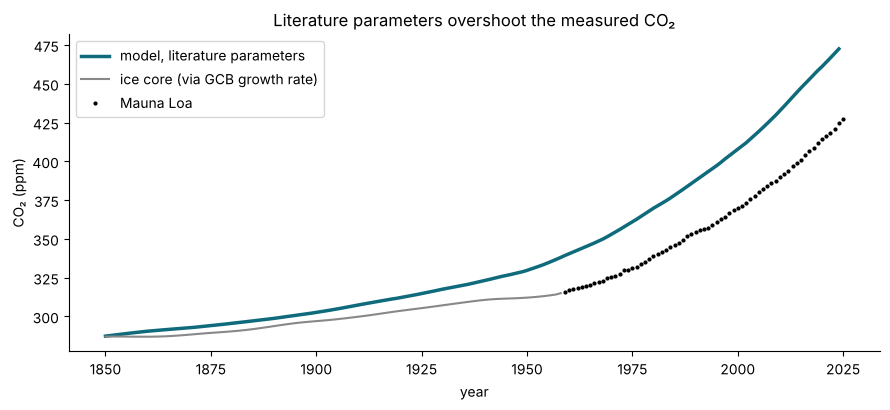

2024: model 472.5 ppm, Mauna Loa 424.6 ppm


In [4]:
lit = scorecard(LIT, "literature")
r = lit["run"]; yrs = r["years"]
obs = observed_co2(); mlo = mauna_loa(); gl = noaa_global()
fig, ax = plt.subplots()
ax.plot(yrs, r["ppm"], lw=2.5, color="#0f6b7c", label="model, literature parameters")
ax.plot(obs.loc[:1958].index, obs.loc[:1958].values, color="#888", lw=1.5, label="ice core (via GCB growth rate)")
ax.plot(mlo.index, mlo.values, "k.", ms=4, label="Mauna Loa")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", title="Literature parameters overshoot the measured CO₂")
ax.legend(); plt.tight_layout(); plt.show()
print(f"2024: model {lit['ppm_2024']:.1f} ppm, Mauna Loa {lit['mlo_2024']:.1f} ppm")

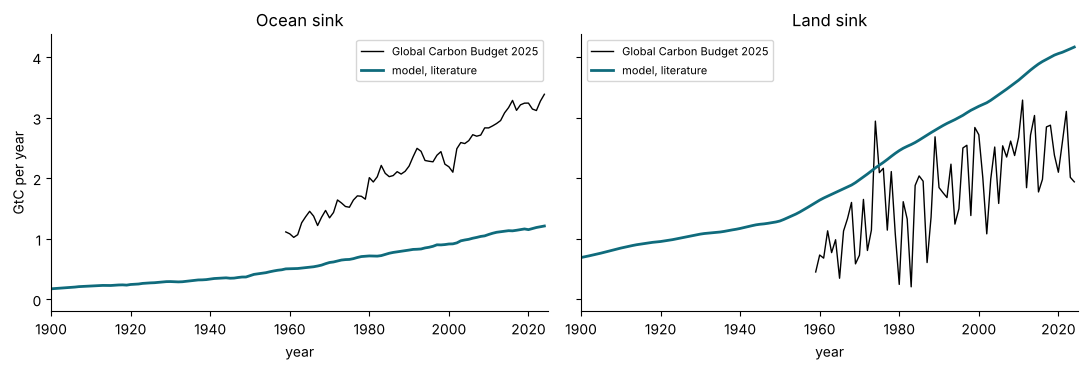

2015-2024 ocean: model 1.17 vs GCB 3.22 ± 0.4 GtC/yr
2015-2024 land:  model 4.04 vs GCB 2.36 ± 0.8 GtC/yr


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, name in [(axs[0], "ocean_sink", "Ocean sink"), (axs[1], "land_sink", "Land sink")]:
    ax.plot(g.loc[1959:2024].index, g.loc[1959:2024, key], color="k", lw=1, label="Global Carbon Budget 2025")
    ax.plot(yrs, r[key], color="#0f6b7c", lw=2, label="model, literature")
    ax.set(title=name, xlabel="year", xlim=(1900, 2025)); ax.legend(fontsize=8)
axs[0].set_ylabel("GtC per year"); plt.tight_layout(); plt.show()
print(f"2015-2024 ocean: model {lit['ocean_sink_2015_2024']:.2f} vs GCB {lit['gcb_ocean_2015_2024']:.2f} ± 0.4 GtC/yr")
print(f"2015-2024 land:  model {lit['land_sink_2015_2024']:.2f} vs GCB {lit['gcb_land_2015_2024']:.2f} ± 0.8 GtC/yr")

**Result of Test 1.** The pulse test passes, but the historical run overshoots by about 48 ppm. The sink panels show why: the model's ocean takes up about a third of what the Global Carbon Budget measures. Because the model is built from mechanisms, the next step is to find which one is responsible.

## 3. Which mechanism limits ocean uptake?

To look at the ocean on its own, the atmosphere is set to the measured CO₂, a concentration-driven run. Each candidate is changed one at a time:

- **k_a**, air–sea gas exchange
- **ocean chemistry**, re-evaluated at warmer surface temperatures with the paper's own formulas
- **k_d**, mixing between the surface and deep ocean

The output is the ocean's total uptake by 1994. [Sabine et al. (2004)](https://oceanfdn.org/sites/default/files/Sabine%20et%20al.%20-%20The%20Oceanic%20Sink%20for%20Anthropogenic%20CO2.pdf) measured it at 118 ± 19 GtC from global ship surveys.

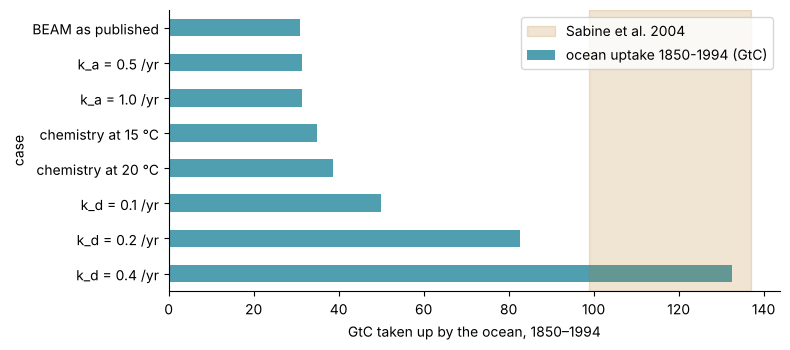

,ocean uptake 1850-1994 (GtC)
case,
BEAM as published,31.0
k_a = 0.5 /yr,31.3
k_a = 1.0 /yr,31.5
chemistry at 15 °C,35.0
chemistry at 20 °C,38.6
k_d = 0.1 /yr,49.9
k_d = 0.2 /yr,82.7
k_d = 0.4 /yr,132.7


In [6]:
cases = [("BEAM as published", LIT)] + \
        [(f"k_a = {v} /yr", Params(k_a=v)) for v in (0.5, 1.0)] + \
        [(f"chemistry at {T} °C", params_at(T)) for T in (15, 20)] + \
        [(f"k_d = {v} /yr", Params(k_d=v)) for v in (0.1, 0.2, 0.4)]
sens = pd.DataFrame([{"case": n, "ocean uptake 1850-1994 (GtC)": ocean_inventory_1994(p)} for n, p in cases]).set_index("case")
ax = sens.plot.barh(legend=False, color="#4f9fb0", figsize=(8, 3.6))
ax.axvspan(SABINE_1994[0]-SABINE_1994[1], SABINE_1994[0]+SABINE_1994[1], color="#b7791f", alpha=.2, label="Sabine et al. 2004")
ax.invert_yaxis(); ax.set_xlabel("GtC taken up by the ocean, 1850–1994"); ax.legend(); plt.tight_layout(); plt.show()
sens.round(1)

**Diagnosis.** Faster gas exchange makes almost no difference: the surface ocean already keeps up with the air. Warmer chemistry helps a little. **Mixing into the deep ocean (k_d) controls the uptake.** The surface box fills quickly and then waits for the deep ocean to take its carbon away.

BEAM's k_d = 0.05 per year (a 20-year exchange time) dates from Bolin & Eriksson (1959), before the tracer surveys that measured how fast the upper ocean actually ventilates. So the main error is a known weak point of the 1959 parameters, not the model's chemistry or structure.

## 4. Test 2: set k_d from ocean data and β from land data, then predict CO₂

The two least certain rates are now set from **reservoir** data. The atmospheric CO₂ record is still never used.

| Rate | Set from | Run type |
|---|---|---|
| k_d (deep mixing) | Ocean uptake by 1994 = 118 GtC (Sabine et al. 2004) | Atmosphere prescribed |
| β (plant fertilization) | Land sink 1960–1999 (GCB 2025) | Atmosphere prescribed |

Everything else is then a prediction: the atmosphere from 1850 to 2024, the ocean and land sinks from 2015 to 2024, the pulse test and its ocean/land split, and the pH decline.

In [7]:
kd = constrain_kd(); kd_lo, kd_hi = constrain_kd(SABINE_1994[0]-SABINE_1994[1]), constrain_kd(SABINE_1994[0]+SABINE_1994[1])
beta = constrain_beta()
print(f"k_d = {kd:.3f} per year (range {kd_lo:.2f}-{kd_hi:.2f} from the ±19 GtC uncertainty); exchange time {1/kd:.1f} yr instead of 20 yr")
print(f"beta = {beta:.3f} (literature range 0.38-0.4, Enting et al. 1994)")
CON = Params(k_d=kd, beta=beta)
con = scorecard(CON, "constrained")

k_d = 0.334 per year (range 0.26-0.42 from the ±19 GtC uncertainty); exchange time 3.0 yr instead of 20 yr
beta = 0.345 (literature range 0.38-0.4, Enting et al. 1994)


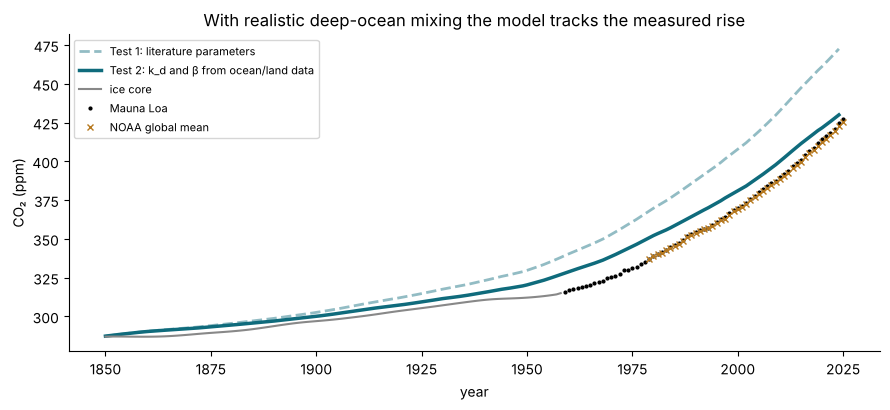

2024: model 430.0 ppm vs Mauna Loa 424.6 ppm


In [8]:
fig, ax = plt.subplots()
rc = con["run"]
ax.plot(yrs, r["ppm"], lw=2, color="#0f6b7c", alpha=.45, ls="--", label="Test 1: literature parameters")
ax.plot(yrs, rc["ppm"], lw=2.5, color="#0f6b7c", label="Test 2: k_d and β from ocean/land data")
ax.plot(obs.loc[:1958].index, obs.loc[:1958].values, color="#888", lw=1.5, label="ice core")
ax.plot(mlo.index, mlo.values, "k.", ms=4, label="Mauna Loa")
ax.plot(gl.index, gl.values, "x", color="#b7791f", ms=4, label="NOAA global mean")
ax.set(xlabel="year", ylabel="CO₂ (ppm)", title="With realistic deep-ocean mixing the model tracks the measured rise")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"2024: model {con['ppm_2024']:.1f} ppm vs Mauna Loa {con['mlo_2024']:.1f} ppm")

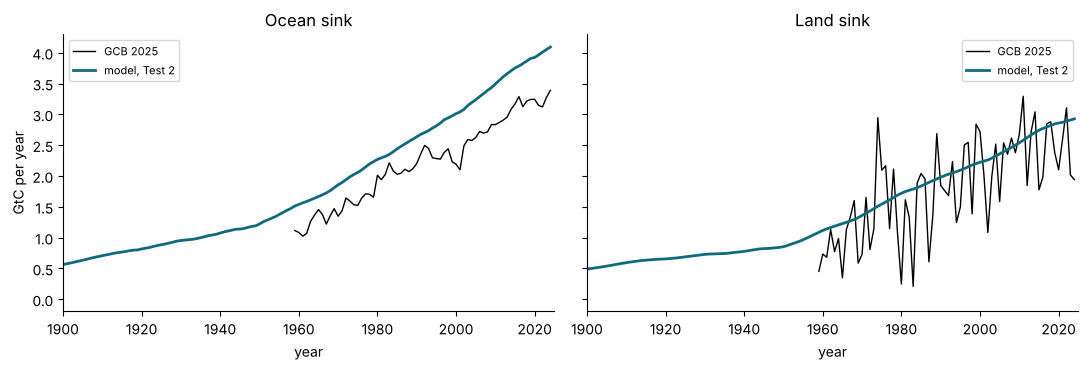

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, name in [(axs[0], "ocean_sink", "Ocean sink"), (axs[1], "land_sink", "Land sink")]:
    ax.plot(g.loc[1959:2024].index, g.loc[1959:2024, key], color="k", lw=1, label="GCB 2025")
    ax.plot(yrs, rc[key], color="#0f6b7c", lw=2, label="model, Test 2")
    ax.set(title=name, xlabel="year", xlim=(1900, 2025)); ax.legend(fontsize=8)
axs[0].set_ylabel("GtC per year"); plt.tight_layout(); plt.show()

## 5. Scorecard

Rows marked *used to set* were used to choose a rate in Test 2, so they don't count as tests there. Everything else is a prediction.

In [10]:
def row(name, pub, unc, key, fmt="{:.2f}", used=False):
    out = {"check": name, "published": (f"{pub} ± {unc}" if unc is not None else str(pub)) if pub is not None else "-"}
    for res in (lit, con):
        v = res[key]
        ok = "" if unc is None else (" ✓" if abs(v - pub) <= unc else " ✗")
        out[res["label"]] = fmt.format(v) + ok
    if used: out["constrained"] += " (used to set)"
    return out
card = pd.DataFrame([
    row("Pulse: airborne after 1000 yr", .25, .09, "pulse_atm_1000"),
    row("Pulse: ocean share after 1000 yr", .59, .12, "pulse_ocean_1000"),
    row("Pulse: land share after 1000 yr", .16, .14, "pulse_land_1000"),
    row("Ocean sink 2015-2024 (GtC/yr)", 3.22, .4, "ocean_sink_2015_2024"),
    row("Land sink 2015-2024 (GtC/yr)", 2.36, .8, "land_sink_2015_2024"),
    row("Surface pH drop 1850-2000", .11, .03, "ph_drop_1850_2000", "{:.3f}"),
    row("CO2 in 2024 (ppm)", 424.6, None, "ppm_2024", "{:.1f}"),
    row("RMSE vs Mauna Loa (ppm)", None, None, "rmse_mlo", "{:.1f}"),
    row("RMSE vs NOAA global mean (ppm)", None, None, "rmse_noaa_global", "{:.1f}"),
    row("RMSE vs ice core 1850-1958 (ppm)", None, None, "rmse_ice_core_1850_1958", "{:.1f}"),
]).set_index("check")
card

,published,literature,constrained
check,,,
Pulse: airborne after 1000 yr,0.25 ± 0.09,0.25 ✓,0.23 ✓
Pulse: ocean share after 1000 yr,0.59 ± 0.12,0.49 ✓,0.57 ✓
Pulse: land share after 1000 yr,0.16 ± 0.14,0.25 ✓,0.20 ✓
Ocean sink 2015-2024 (GtC/yr),3.22 ± 0.4,1.17 ✗,3.92 ✗
Land sink 2015-2024 (GtC/yr),2.36 ± 0.8,4.04 ✗,2.84 ✓
Surface pH drop 1850-2000,0.11 ± 0.03,0.133 ✓,0.101 ✓
CO2 in 2024 (ppm),424.6,472.5,430.0
RMSE vs Mauna Loa (ppm),-,36.2,11.6
RMSE vs NOAA global mean (ppm),-,40.5,11.7


## 6. The Global Carbon Budget itself doesn't close

A model that matched every published sink exactly would still overshoot. The Global Carbon Budget reports a **budget imbalance**: emissions minus everything it can account for. Summed over 1850–2024, that is:

In [11]:
imb = g.loc[1850:2024, "imbalance"].sum()
print(f"Cumulative budget imbalance 1850-2024: {imb:.0f} GtC = {imb/GTC_PER_PPM:.0f} ppm")
print(f"  of which before 1959: {g.loc[1850:1958,'imbalance'].sum()/GTC_PER_PPM:.0f} ppm")
off = pd.Series(rc["ppm"], index=yrs) - obs.loc[1850:2024]
print(f"Test 2 model minus observed: 1959 {off[1959]:+.1f} ppm, 2024 {off[2024]:+.1f} ppm")

Cumulative budget imbalance 1850-2024: 80 GtC = 38 ppm
  of which before 1959: 21 ppm
Test 2 model minus observed: 1959 +12.1 ppm, 2024 +5.4 ppm


Most of the model's remaining offset (about +12 ppm) builds up before 1959, when the budget's own imbalance is largest (about 21 ppm). Ice-core CO₂ even levelled off in the 1940s while emissions kept rising. The early land-use emissions are the least certain input, which makes them the most likely cause.

## 7. Limitations

- **Two-layer ocean.** One mixing rate can't match both the 1994 inventory and the recent sink: with k_d set from the inventory, the 2015–2024 sink is about 3.9 GtC/yr against the GCB's 3.2 ± 0.4. A real ocean has a gradual thermocline, not two layers.
- **Ocean chemistry.** The model's Revelle factor in 2000 is about 17. That is high compared with the roughly 11 implied by [Jiang et al. (2019)](https://www.nature.com/articles/s41598-019-55039-4), whose RCP8.5 projection has it rising by 3.7 (about 34%) after 2000. The cause is BEAM's 10 °C constants and fixed alkalinity.
- **Simple land.** A single fertilization factor, with no temperature or nitrogen limits, and an approximate turnover time.
- **No climate feedback.** Warming that reduces ocean and land uptake isn't included.